**Este notebook tem como objetivo utilizar ferramentas do Python para facilitar cálculos matemáticos e a criação de gráficos. Cada trecho de código será explicado detalhadamente, visando tornar o entendimento mais acessível para o leitor.**

1) No código seguinte é feito a importação das bibliotecas utilizadas e o carregamento do arquivo utilizado.

In [106]:
# Importar bibliotecas necessárias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import scipy.stats as stats
from statsmodels.stats.diagnostic import lilliefors
from matplotlib.ticker import FuncFormatter

In [107]:
# Carregar os arquivos CSV
df_gw = pd.read_csv("../../data/Grupo com registro entre 07-2024 a 06-2025- GW.csv", sep='\t')

C:\Users\Inteli\AppData\Local\Temp\ipykernel_27408\1456239399.py:2: DtypeWarning: Columns (11,21) have mixed types. Specify dtype option on import or set low_memory=False.
  df_gw = pd.read_csv("../../data/Grupo com registro entre 07-2024 a 06-2025- GW.csv", sep='\t')


2) Na seguinte parte é usado um código para ver as 5 primeiras informações da planilha, que irão auxiliar os próximos códigos

In [108]:
df_gw.head() # mostra as primeiras linhas e os nomes de colunas


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,pagador_cidade,qtd_acessos_pagador,pagador_dt_ultimo_acesso,pagador_cnpjcpf,pagador_inscricao_hash,valor_abatimento,tipo_juros,juros,tipo_multa,multa
0,212,658,380217446,2024-07-03,BAIXADO,2024-07-29,8528.52,\N,\N,BANCO DO BRASIL,...,Mage,3,2024-08-10 15:58:02,CNPJ,01fa7845e68846b4f804f5df66393cf022c5266cfaf688...,0.0,M,2.84,P,10.00
1,212,658,380217447,2024-07-03,LIQUIDADO,2024-08-27,8528.52,2024-08-23,8528.52,BANCO DO BRASIL,...,Mage,1,2024-08-09 16:35:15,CNPJ,01fa7845e68846b4f804f5df66393cf022c5266cfaf688...,0.0,M,2.84,P,10.00
2,212,658,380217448,2024-07-03,LIQUIDADO,2024-09-26,8528.52,2024-09-23,8528.52,BANCO DO BRASIL,...,Mage,3,2024-09-10 14:30:58,CNPJ,01fa7845e68846b4f804f5df66393cf022c5266cfaf688...,0.0,M,2.84,P,10.00
3,212,658,380217449,2024-07-03,LIQUIDADO,2024-10-28,8528.52,2024-10-24,8528.52,BANCO DO BRASIL,...,Mage,2,2024-09-11 11:54:13,CNPJ,01fa7845e68846b4f804f5df66393cf022c5266cfaf688...,0.0,M,2.84,P,10.00
4,212,658,380217450,2024-07-03,LIQUIDADO,2024-11-25,8528.52,2024-11-26,8528.52,BANCO DO BRASIL,...,Mage,2,2024-09-11 11:55:11,CNPJ,01fa7845e68846b4f804f5df66393cf022c5266cfaf688...,0.0,M,2.84,P,10.00


3) No código seguinte é usado comandos da biblioteca pandas para descobrir a quantidade de valores diferentes de uma dada coluna.

In [109]:

# Mostra valores únicos
print(df_gw['vl_boleto'].nunique())

24106


4) Nos códigos à frente são feitas as configurações dos parâmetros como o $\alpha$, também são feitos os cálculos para a descoberta do p-valor de cada variável, além de já estar ajustada para as conclusões.

In [110]:
# Configuração
alpha = 0.05  # nível de significância
variaveis = ['vl_boleto', 'vl_pagto', 'juros', 'qtd_acessos_pagador', 'multa']  # ajuste para as colunas do seu dataset


In [111]:
# --- Loop para rodar o teste em cada variável ---
resultados = []

for var in variaveis:
    # Garante que a coluna é numérica e remove valores ausentes
    x = pd.to_numeric(df_gw[var], errors='coerce').dropna()
    
    # Teste de Lilliefors (H0: distribuição é normal com μ e σ estimados)
    stat, p = lilliefors(x, dist='norm')
    
    # Conclusão com base no p-valor
    if p > alpha:
        conclusao = "Não rejeita H₀ (≈ normal)"
    else:
        conclusao = "Rejeita H₀ (não normal)"
    
    resultados.append([var, f"{p:.4f}", conclusao])

In [112]:
# --- Cria tabela organizada ---
tabela = pd.DataFrame(resultados, columns=['Variável', 'p-valor', 'Conclusão'])
print(tabela)

              Variável p-valor                Conclusão
0            vl_boleto  0.0010  Rejeita H₀ (não normal)
1             vl_pagto  0.0010  Rejeita H₀ (não normal)
2                juros  0.0010  Rejeita H₀ (não normal)
3  qtd_acessos_pagador  0.0010  Rejeita H₀ (não normal)
4                multa  0.0010  Rejeita H₀ (não normal)


5) O bloco abaixo contém o coodigo que realiza a limpeza dos dados, impedindo falhas em futuros códigos que usem essas variáveis

In [113]:
for var in variaveis:
    # Limpeza
    df_gw[var] = (
        df_gw[var]
        .astype(str)
        .str.replace(',', '.', regex=False)
        .str.replace('[^0-9.]', '', regex=True)
    )
    
    # Substitui strings vazias por NaN
    df_gw[var] = df_gw[var].replace('', np.nan)
    
    # Converte para float
    df_gw[var] = df_gw[var].astype(float)
    
    print(f"{var} convertida para float. Valores únicos: {df_gw[var].nunique()}")


vl_boleto convertida para float. Valores únicos: 24106
vl_pagto convertida para float. Valores únicos: 22689
juros convertida para float. Valores únicos: 2079
qtd_acessos_pagador convertida para float. Valores únicos: 48
multa convertida para float. Valores únicos: 959


6) No código seguinte é plotado o histograma referente a cada variável e o cálculo de suas médias e medianas.

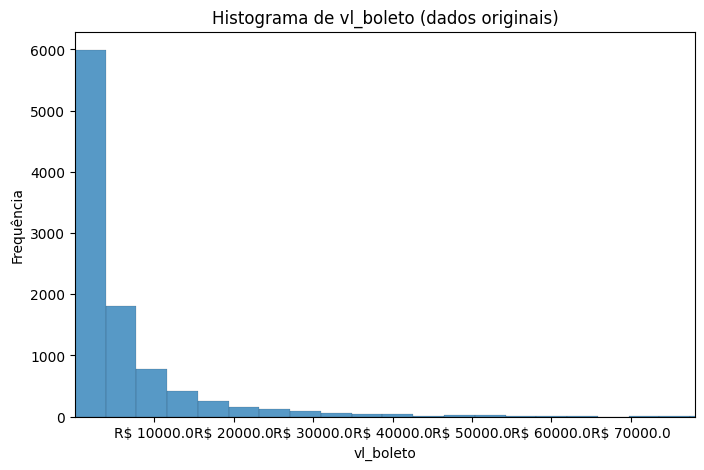

Variável: vl_boleto
Média: R$ 8,278.10, Mediana: R$ 2,799.24
Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,
com alguns valores isolados muito maiores.



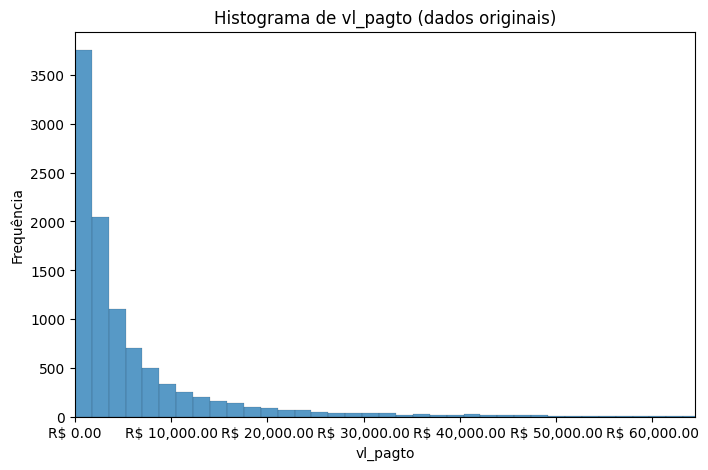

Variável: vl_pagto
Média: R$ 7,302.77, Mediana: R$ 2,708.33
Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,
com alguns valores isolados muito maiores.



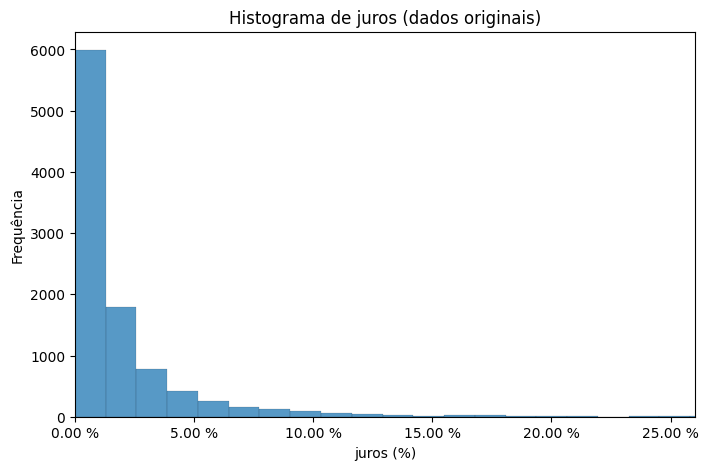

Variável: juros
Média: 2.76%, Mediana: 0.94%
Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,
com alguns valores isolados muito maiores.



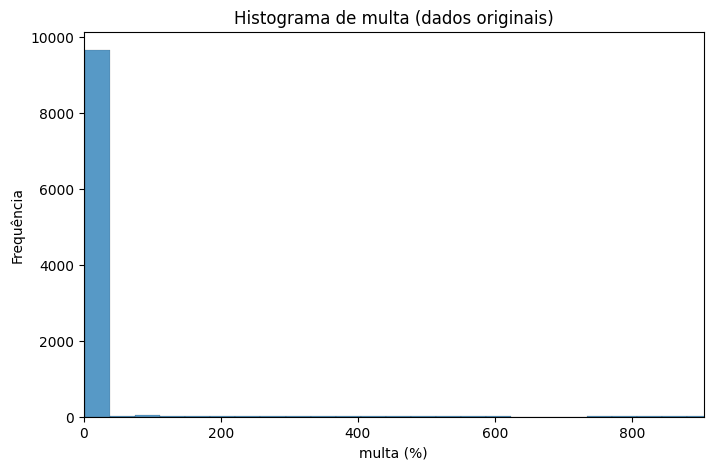

Variável: multa
Média: 44.54%, Mediana: 10.00%
Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,
com alguns valores isolados muito maiores.



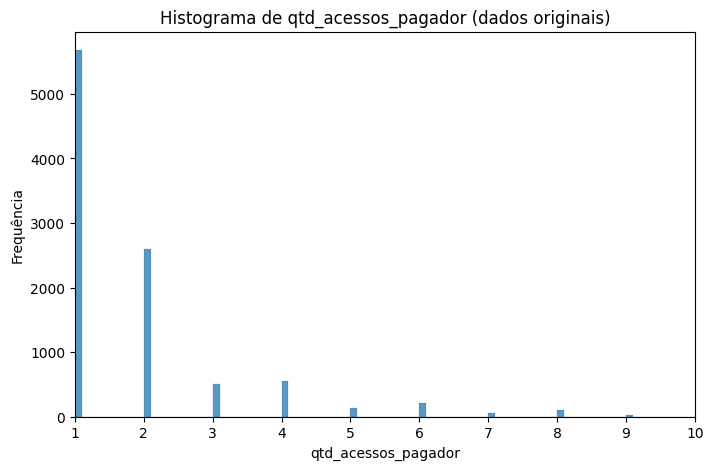

Variável: qtd_acessos_pagador
Média: 2 acessos, Mediana: 1 acessos
Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,
com alguns valores isolados muito maiores.



In [114]:
import matplotlib.pyplot as plt
import seaborn as sns

# Máximo de pontos para plotar
max_plot = 10000

# ===========================
# 1️⃣ vl_boleto (R$)
# ===========================
x = df_gw['vl_boleto'].dropna()
x_plot = x if x.size <= max_plot else x.sample(max_plot, random_state=42)

plt.figure(figsize=(8,5))
sns.histplot(x_plot, bins=500, kde=False)
plt.xlim(x.min(), x.quantile(0.99))
formatter = FuncFormatter(lambda val, _: f"R$ {val:}")
plt.gca().xaxis.set_major_formatter(formatter)
plt.title('Histograma de vl_boleto (dados originais)')
plt.xlabel('vl_boleto')
plt.ylabel('Frequência')
plt.show()

media = x.mean()
mediana = x.median()
print("Variável: vl_boleto")
print(f"Média: R$ {media:,.2f}, Mediana: R$ {mediana:,.2f}")
print("Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,")
print("com alguns valores isolados muito maiores.\n")

# ===========================
# 2️⃣ vl_pagto (R$)
# ===========================
x = df_gw['vl_pagto'].dropna()
x_plot = x if x.size <= max_plot else x.sample(max_plot, random_state=42)

plt.figure(figsize=(8,5))
sns.histplot(x_plot, bins=500, kde=False)
plt.xlim(x.min(), x.quantile(0.99))
formatter = FuncFormatter(lambda val, _: f"R$ {val:,.2f}")
plt.gca().xaxis.set_major_formatter(formatter)
plt.title('Histograma de vl_pagto (dados originais)')
plt.xlabel('vl_pagto')
plt.ylabel('Frequência')
plt.show()

media = x.mean()
mediana = x.median()
print("Variável: vl_pagto")
print(f"Média: R$ {media:,.2f}, Mediana: R$ {mediana:,.2f}")
print("Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,")
print("com alguns valores isolados muito maiores.\n")

# ===========================
# 3️⃣ juros (%)
# ===========================
x = df_gw['juros'].dropna()
x_plot = x if x.size <= max_plot else x.sample(max_plot, random_state=42)

plt.figure(figsize=(8,5))
sns.histplot(x_plot, bins=500, kde=False)
plt.xlim(0, x.quantile(0.99))
formatter = FuncFormatter(lambda val, _: f"{val:,.2f} %")
plt.gca().xaxis.set_major_formatter(formatter)
plt.title('Histograma de juros (dados originais)')
plt.xlabel('juros (%)')
plt.ylabel('Frequência')
plt.show()

media = x.mean()
mediana = x.median()
print("Variável: juros")
print(f"Média: {media:.2f}%, Mediana: {mediana:.2f}%")
print("Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,")
print("com alguns valores isolados muito maiores.\n")

# ===========================
# 4️⃣ multa (%)
# ===========================
x = df_gw['multa'].dropna()
x_plot = x if x.size <= max_plot else x.sample(max_plot, random_state=42)

plt.figure(figsize=(8,5))
sns.histplot(x_plot, bins=500, kde=False)
plt.xlim(0, x.quantile(0.99))
formatter = FuncFormatter(lambda val, _: f"{val:} %")
plt.title('Histograma de multa (dados originais)')
plt.xlabel('multa (%)')
plt.ylabel('Frequência')
plt.show()

media = x.mean()
mediana = x.median()
print("Variável: multa")
print(f"Média: {media:.2f}%, Mediana: {mediana:.2f}%")
print("Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,")
print("com alguns valores isolados muito maiores.\n")

# ===========================
# 5️⃣ qtd_acessos_pagador (contagem)
# ===========================
x = df_gw['qtd_acessos_pagador'].dropna()
x_plot = x if x.size <= max_plot else x.sample(max_plot, random_state=42)

plt.figure(figsize=(8,5))
sns.histplot(x_plot, bins=500, kde=False)
plt.xlim(x.min(), x.quantile(0.99))
plt.title('Histograma de qtd_acessos_pagador (dados originais)')
plt.xlabel('qtd_acessos_pagador')
plt.ylabel('Frequência')
plt.show()

media = x.mean()
mediana = x.median()
print("Variável: qtd_acessos_pagador")
print(f"Média: {media:.0f} acessos, Mediana: {mediana:.0f} acessos")
print("Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,")
print("com alguns valores isolados muito maiores.\n")

7) O código a seguir realiza o cálculo dos dados estatísticos das variáveis escolhidas.

In [115]:
estatisticas = []

for var in variaveis:
    x = pd.to_numeric(df_gw[var], errors='coerce').dropna()
    estatisticas.append({
        "Variável": var,
        "Mínimo": x.min(),
        "Máximo": x.max(),
        "Média": x.mean(),
        "Mediana": x.median(),
        "Desvio padrão (populacional)": x.std(ddof=0)
    })

df_estatisticas = pd.DataFrame(estatisticas)
print(df_estatisticas)


              Variável  Mínimo      Máximo        Média  Mediana  \
0            vl_boleto    0.05  3325737.15  8278.098431  2799.24   
1             vl_pagto    0.00  1936467.04  7302.765326  2708.33   
2                juros    0.00     1108.58     2.763921     0.94   
3  qtd_acessos_pagador    1.00       86.00     1.975555     1.00   
4                multa    1.46    18325.01    44.540882    10.00   

   Desvio padrão (populacional)  
0                  46433.895360  
1                  30500.663670  
2                     15.480987  
3                      2.196959  
4                    326.982654  


8) O cógio a frente é responsável por criar os histográmas com os dados já escalonados.

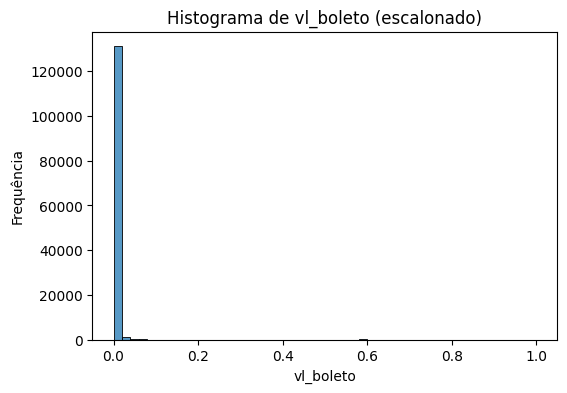

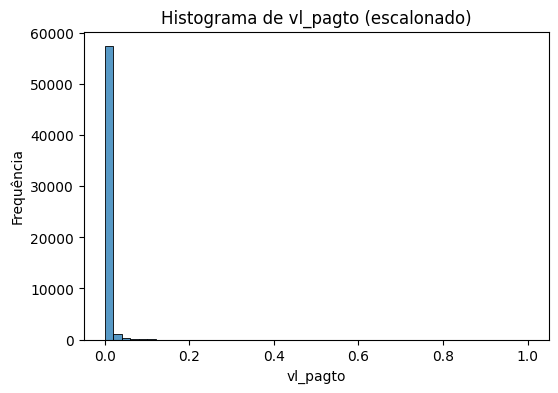

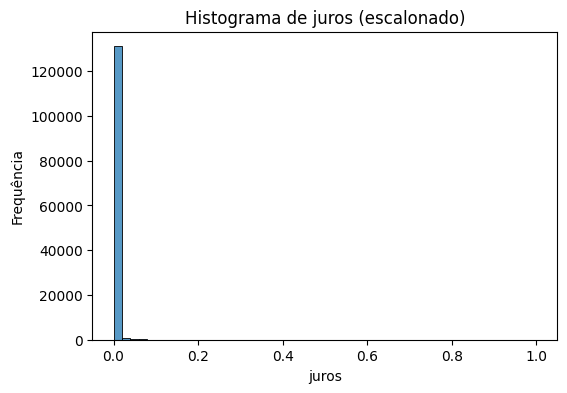

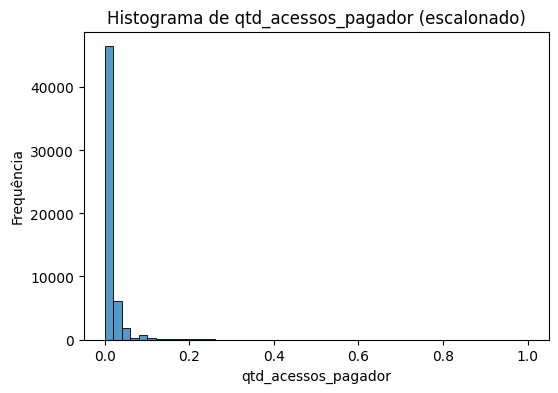

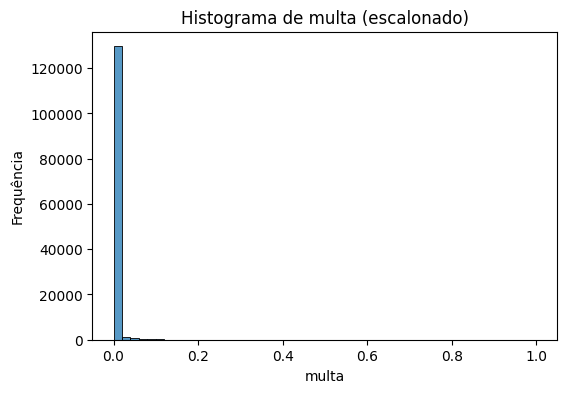

In [116]:
# Criar cópia antes do escalonamento
df_gw_orig = df_gw.copy()

# Criar escalonadores
scaler_minmax = MinMaxScaler()
scaler_std = StandardScaler()

# Normalização
df_gw[['vl_boleto', 'vl_pagto', 'qtd_acessos_pagador']] = scaler_minmax.fit_transform(df_gw[['vl_boleto', 'vl_pagto', 'qtd_acessos_pagador']])

# Padronização
df_gw[['juros', 'multa']] = scaler_minmax.fit_transform(df_gw[['juros', 'multa']])

# Plot histogramas dos dados escalonados
for var in variaveis:
    plt.figure(figsize=(6,4))
    sns.histplot(df_gw[var], bins=50, kde=False)
    plt.title(f'Histograma de {var} (escalonado)')
    plt.xlabel(var)
    plt.ylabel('Frequência')
    plt.show()


9) O código seguinte é responsável por apresentar os 10 primeiros dados de todas as variáveis escolhidas, antes e depois do escalonamento.

In [117]:
# 10 primeiros registros originais
print("10 primeiros registros (originais):")
display(df_gw_orig[variaveis].dropna().head(10))

# 10 primeiros registros escalonados
print("10 primeiros registros (escalonados):")
display(df_gw[variaveis].dropna().head(10))

10 primeiros registros (originais):


,vl_boleto,vl_pagto,juros,qtd_acessos_pagador,multa
1,8528.52,8528.52,2.84,1.0,10.0
2,8528.52,8528.52,2.84,3.0,10.0
3,8528.52,8528.52,2.84,2.0,10.0
4,8528.52,8528.52,2.84,2.0,10.0
5,8528.49,8528.49,2.84,2.0,10.0
6,726.97,726.97,0.24,1.0,10.0
7,726.97,726.97,0.24,1.0,10.0
9,726.97,726.97,0.24,2.0,10.0
10,726.97,726.97,0.24,2.0,10.0
11,726.97,726.97,0.24,2.0,10.0


10 primeiros registros (escalonados):


,vl_boleto,vl_pagto,juros,qtd_acessos_pagador,multa
1,0.002564,0.004404,0.002562,0.000000,0.000466
2,0.002564,0.004404,0.002562,0.023529,0.000466
3,0.002564,0.004404,0.002562,0.011765,0.000466
4,0.002564,0.004404,0.002562,0.011765,0.000466
5,0.002564,0.004404,0.002562,0.011765,0.000466
6,0.000219,0.000375,0.000216,0.000000,0.000466
7,0.000219,0.000375,0.000216,0.000000,0.000466
9,0.000219,0.000375,0.000216,0.011765,0.000466
10,0.000219,0.000375,0.000216,0.011765,0.000466
11,0.000219,0.000375,0.000216,0.011765,0.000466
